# Modelo KNN para predecir el ICVU

* Tipo: supervisado, **clasificación** ordinal (variable objetivo: nivel ICVU 2025 codificado 1 = Bajo … 4 = Alto)
* Modelo: KNN (`KNeighborsClassifier`)
* Unidad de análisis: **comuna** (una fila por comuna, generada por `data_obtain_comunas.ipynb`)



### Librerías
La celda siguiente instala lo necesario en el kernel actual (solo hace falta la primera vez).

In [136]:
%pip install -q pandas numpy scikit-learn matplotlib joblib seaborn

Note: you may need to restart the kernel to use updated packages.


In [137]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

### Parámetros

In [138]:
DEBUG = True
SEMILLA = 42

DATASET = "dataset_comunas.csv"   # salida de data_obtain_comunas.ipynb (con ICVU unido a features)
GUARDAR_MODELO = "modelo_knn_icvu_clasif.joblib"

TEST_SIZE = 0.3


## Cargar dataset

In [139]:
df = pd.read_csv(DATASET)
df = df.drop(columns=["nivel_2025", "comuna"])
df["ICVU_nivel"] = df["ICVU_nivel"].astype(int)

print("Filas, Columnas")
print(df.shape)
print(df["ICVU_nivel"].value_counts().sort_index())   # cuántas comunas hay en cada nivel
#print(df)

Filas, Columnas
(42, 125)
ICVU_nivel
1    13
2    13
3     7
4     9
Name: count, dtype: int64


### Selección de variables

In [140]:
columnas = [c for c in df.columns if c.startswith("x10k_") or c.startswith("pct_area_")]
columnas.append("hab_km2")

X = df[columnas]
y = df["ICVU_nivel"]

## Modelo

#### Separacion Train/Test

In [141]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=42, stratify=y
)

#### Parametros del modelo

* Rellenar missing values con mediana
* Escalar StandardScaler
* Modelo KNN

In [142]:
modelo = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),   # rellena datos faltantes
    ("escalar", StandardScaler()),                   # pone todas las variables en la misma escala
    ("knn", KNeighborsClassifier()),    # el clasificador
])

In [143]:
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

#### Metricas de Evaluacion

Accuracy: 0.6153846153846154
              precision    recall  f1-score   support

           1       1.00      0.75      0.86         4
           2       0.50      1.00      0.67         4
           3       0.00      0.00      0.00         2
           4       1.00      0.33      0.50         3

    accuracy                           0.62        13
   macro avg       0.62      0.52      0.51        13
weighted avg       0.69      0.62      0.58        13



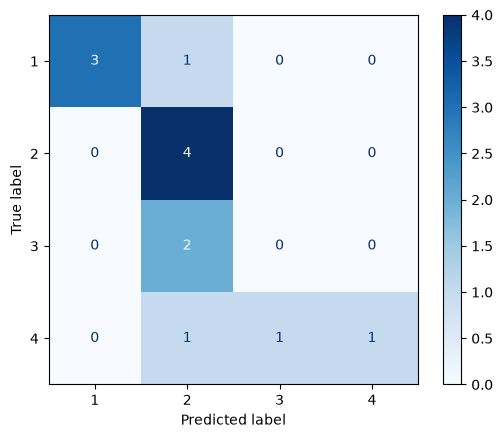

In [144]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))   # precision y recall por nivel

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")

## Cross Validation

In [149]:
from sklearn.model_selection import cross_val_score
cross_val_score(modelo, X, y, cv=5)

array([0.22222222, 0.55555556, 0.25      , 0.5       , 0.375     ])